In [1]:

# PesaPap Growth Analytics
# PLP Data Analytics Assignment 7

import sqlite3
import pandas as pd
import numpy as np
from pathlib import Path

# Define project paths
PROJECT_DIR = Path.cwd()
DATABASE_PATH = PROJECT_DIR / "pesapap.db"
REPORTS_DIR = PROJECT_DIR / "reports"

# Display project information
print("PesaPap Growth Analytics")
print("-" * 40)
print("Project directory:", PROJECT_DIR)
print("Database exists:", DATABASE_PATH.exists())
print("Reports directory exists:", REPORTS_DIR.exists())
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


PesaPap Growth Analytics
----------------------------------------
Project directory: c:\Users\georg\Documents\plp-da-a7-pesapap-growth-analytics
Database exists: True
Reports directory exists: True
Pandas version: 3.1.1
NumPy version: 2.5.4


In [2]:

# Load PesaPap datasets

users = pd.read_csv(PROJECT_DIR / "users.csv")
transactions = pd.read_csv(PROJECT_DIR / "transactions.csv")
experiment = pd.read_csv(PROJECT_DIR / "experiment.csv")

# Display dataset dimensions
print("DATASET DIMENSIONS")
print("-" * 45)
print(f"Users: {users.shape[0]:,} rows, {users.shape[1]} columns")
print(f"Transactions: {transactions.shape[0]:,} rows, {transactions.shape[1]} columns")
print(f"Experiment: {experiment.shape[0]:,} rows, {experiment.shape[1]} columns")

# Display column names
print("\nDATASET COLUMNS")
print("-" * 45)

for name, df in {
    "Users": users,
    "Transactions": transactions,
    "Experiment": experiment
}.items():
    print(f"\n{name}:")
    print(df.columns.tolist())

# Preview the users dataset
print("\nUSERS DATA PREVIEW")
display(users.head())

# Preview the transactions dataset
print("\nTRANSACTIONS DATA PREVIEW")
display(transactions.head())

# Preview the experiment dataset
print("\nEXPERIMENT DATA PREVIEW")
display(experiment.head())


DATASET DIMENSIONS
---------------------------------------------
Users: 3,000 rows, 4 columns
Transactions: 12,000 rows, 5 columns
Experiment: 3,000 rows, 3 columns

DATASET COLUMNS
---------------------------------------------

Users:
['user_id', 'signup_date', 'county', 'acquisition_channel']

Transactions:
['txn_id', 'user_id', 'txn_date', 'product', 'amount']

Experiment:
['user_id', 'group', 'converted']

USERS DATA PREVIEW


,user_id,signup_date,county,acquisition_channel
0,1,2026-01-08,Kisumu,Agent
1,2,2026-04-05,Eldoret,Social
2,3,2026-03-18,Nairobi,Referral
3,4,2026-03-08,Nairobi,Referral
4,5,2026-04-06,Kisumu,Agent



TRANSACTIONS DATA PREVIEW


,txn_id,user_id,txn_date,product,amount
0,1,1752,2026-05-11,Airtime,430.0
1,2,1390,2026-03-06,Bill Pay,1245.0
2,3,1418,2026-03-09,Bill Pay,557.0
3,4,357,2026-04-13,Airtime,381.0
4,5,2726,2026-04-07,Send Money,2918.0



EXPERIMENT DATA PREVIEW


,user_id,group,converted
0,1,A,0
1,2,A,0
2,3,A,0
3,4,B,0
4,5,A,0


In [3]:

# DATA QUALITY AUDIT

print("1. MISSING VALUES")
print("-" * 50)

for name, df in {
    "Users": users,
    "Transactions": transactions,
    "Experiment": experiment
}.items():
    print(f"\n{name}:")
    print(df.isnull().sum().to_string())

print("\n2. DUPLICATE PRIMARY KEYS")
print("-" * 50)

print("Duplicate user IDs:", users["user_id"].duplicated().sum())
print("Duplicate transaction IDs:", transactions["txn_id"].duplicated().sum())
print("Duplicate experiment user IDs:", experiment["user_id"].duplicated().sum())

print("\n3. REFERENTIAL INTEGRITY")
print("-" * 50)

unknown_transaction_users = (
    ~transactions["user_id"].isin(users["user_id"])
).sum()

unknown_experiment_users = (
    ~experiment["user_id"].isin(users["user_id"])
).sum()

print("Transactions linked to unknown users:", unknown_transaction_users)
print("Experiment records linked to unknown users:", unknown_experiment_users)

print("\n4. TRANSACTION CHRONOLOGY")
print("-" * 50)

# Convert date columns to datetime for reliable comparison
users["signup_date"] = pd.to_datetime(users["signup_date"])
transactions["txn_date"] = pd.to_datetime(transactions["txn_date"])

transaction_audit = transactions.merge(
    users[["user_id", "signup_date"]],
    on="user_id",
    how="left"
)

pre_signup_count = (
    transaction_audit["txn_date"] <
    transaction_audit["signup_date"]
).sum()

print("Total transactions:", len(transactions))
print("Transactions before signup:", pre_signup_count)
print(
    "Pre-signup transaction percentage:",
    round(pre_signup_count / len(transactions) * 100, 2),
    "%"
)

print("\n5. EXPERIMENT DATA CHECK")
print("-" * 50)

print("Experiment groups:")
print(experiment["group"].value_counts().to_string())

print("\nConversion values:")
print(experiment["converted"].value_counts().to_string())


1. MISSING VALUES
--------------------------------------------------

Users:
user_id                0
signup_date            0
county                 0
acquisition_channel    0

Transactions:
txn_id      0
user_id     0
txn_date    0
product     0
amount      0

Experiment:
user_id      0
group        0
converted    0

2. DUPLICATE PRIMARY KEYS
--------------------------------------------------
Duplicate user IDs: 0
Duplicate transaction IDs: 0
Duplicate experiment user IDs: 0

3. REFERENTIAL INTEGRITY
--------------------------------------------------
Transactions linked to unknown users: 0
Experiment records linked to unknown users: 0

4. TRANSACTION CHRONOLOGY
--------------------------------------------------
Total transactions: 12000
Transactions before signup: 3737
Pre-signup transaction percentage: 31.14 %

5. EXPERIMENT DATA CHECK
--------------------------------------------------
Experiment groups:
group
B    1557
A    1443

Conversion values:
converted
0    2634
1     366


In [4]:

# COMPACT DATA QUALITY AUDIT SUMMARY

print("PESAPAP DATA QUALITY SUMMARY")
print("=" * 45)

# Duplicate primary keys
print("\nDUPLICATE RECORDS")
print("Duplicate user IDs:", users["user_id"].duplicated().sum())
print("Duplicate transaction IDs:", transactions["txn_id"].duplicated().sum())
print("Duplicate experiment user IDs:", experiment["user_id"].duplicated().sum())

# Referential integrity
unknown_transaction_users = (
    ~transactions["user_id"].isin(users["user_id"])
).sum()

unknown_experiment_users = (
    ~experiment["user_id"].isin(users["user_id"])
).sum()

print("\nREFERENTIAL INTEGRITY")
print("Unknown transaction users:", unknown_transaction_users)
print("Unknown experiment users:", unknown_experiment_users)

# Transaction chronology
pre_signup_count = (
    transaction_audit["txn_date"] <
    transaction_audit["signup_date"]
).sum()

print("\nTRANSACTION CHRONOLOGY")
print("Pre-signup transactions:", pre_signup_count)
print(
    "Pre-signup percentage:",
    round(pre_signup_count / len(transactions) * 100, 2),
    "%"
)

# Experiment allocation
print("\nEXPERIMENT GROUP SIZES")
print(experiment["group"].value_counts().sort_index().to_string())

print("\nEXPERIMENT CONVERSION COUNTS")
print(
    experiment.groupby(["group", "converted"])
    .size()
    .unstack(fill_value=0)
    .to_string()
)

print("\nOVERALL CONVERSION RATE:",
      round(experiment["converted"].mean() * 100, 2), "%")


PESAPAP DATA QUALITY SUMMARY

DUPLICATE RECORDS
Duplicate user IDs: 0
Duplicate transaction IDs: 0
Duplicate experiment user IDs: 0

REFERENTIAL INTEGRITY
Unknown transaction users: 0
Unknown experiment users: 0

TRANSACTION CHRONOLOGY
Pre-signup transactions: 3737
Pre-signup percentage: 31.14 %

EXPERIMENT GROUP SIZES
group
A    1443
B    1557

EXPERIMENT CONVERSION COUNTS
converted     0    1
group               
A          1292  151
B          1342  215

OVERALL CONVERSION RATE: 12.2 %


In [5]:

# PESAPAP KPI SCORECARD

# Calculate core business metrics
total_users = len(users)
total_transactions = len(transactions)
total_gtv = transactions["amount"].sum()
average_transaction_value = transactions["amount"].mean()

pre_signup_transactions = (
    transaction_audit["txn_date"] <
    transaction_audit["signup_date"]
).sum()

valid_transactions = total_transactions - pre_signup_transactions

total_conversions = experiment["converted"].sum()
overall_conversion_rate = experiment["converted"].mean() * 100

# Create KPI scorecard
kpi_scorecard = pd.DataFrame({
    "Metric": [
        "Registered Users",
        "Recorded Transactions",
        "Gross Transaction Value (KES)",
        "Average Transaction Value (KES)",
        "Pre-signup Transactions",
        "Pre-signup Transaction Rate (%)",
        "Chronologically Valid Transactions",
        "Experiment Participants",
        "Experiment Conversions",
        "Overall Experiment Conversion Rate (%)"
    ],
    "Value": [
        total_users,
        total_transactions,
        round(total_gtv, 2),
        round(average_transaction_value, 2),
        pre_signup_transactions,
        round(pre_signup_transactions / total_transactions * 100, 2),
        valid_transactions,
        len(experiment),
        total_conversions,
        round(overall_conversion_rate, 2)
    ]
})

print("PESAPAP GROWTH ANALYTICS — KPI SCORECARD")
print("=" * 65)

display(kpi_scorecard)


PESAPAP GROWTH ANALYTICS — KPI SCORECARD


,Metric,Value
0,Registered Users,3000.00
1,Recorded Transactions,12000.00
2,Gross Transaction Value (KES),15979309.00
3,Average Transaction Value (KES),1331.61
4,Pre-signup Transactions,3737.00
5,Pre-signup Transaction Rate (%),31.14
6,Chronologically Valid Transactions,8263.00
7,Experiment Participants,3000.00
8,Experiment Conversions,366.00
9,Overall Experiment Conversion Rate (%),12.20


In [6]:
# METRIC DICTIONARY

metric_dictionary = pd.DataFrame({
    "Metric": [
        "Registered Users",
        "Recorded Transactions",
        "Gross Transaction Value (KES)",
        "Average Transaction Value (KES)",
        "Pre-signup Transactions",
        "Pre-signup Transaction Rate (%)",
        "Chronologically Valid Transactions",
        "Experiment Participants",
        "Experiment Conversions",
        "Overall Experiment Conversion Rate (%)"
    ],
    "Definition": [
        "Total number of registered users.",
        "Total number of transactions recorded in the dataset.",
        "Total monetary value of all recorded transactions.",
        "Average monetary value per recorded transaction.",
        "Transactions dated before the corresponding user's signup date.",
        "Percentage of recorded transactions dated before signup.",
        "Transactions dated on or after the corresponding user's signup date.",
        "Total users included in the experiment dataset.",
        "Total experiment participants recorded as converted.",
        "Percentage of experiment participants recorded as converted."
    ],
    "Calculation": [
        "Count of users",
        "Count of transaction records",
        "Sum of transaction amounts",
        "Total transaction value / transaction count",
        "Count where transaction date < signup date",
        "Pre-signup transactions / recorded transactions × 100",
        "Recorded transactions - pre-signup transactions",
        "Count of experiment records",
        "Sum of the converted column",
        "Experiment conversions / experiment participants × 100"
    ],
    "Interpretation and Caveats": [
        "Measures the registered customer base.",
        "Represents recorded activity, not necessarily valid post-signup activity.",
        "Includes the value of all recorded transactions, including pre-signup records.",
        "Describes the average value of a recorded transaction.",
        "Indicates a chronology data-quality issue requiring investigation.",
        "A high rate may distort customer activity and growth analysis.",
        "Use this population for post-signup activity analysis.",
        "Represents the experiment sample size.",
        "Represents recorded conversions across both experiment groups.",
        "Overall rate does not show the difference between experiment groups."
    ]
})

print("PESAPAP METRIC DICTIONARY")
print("=" * 65)

display(metric_dictionary)

PESAPAP METRIC DICTIONARY


,Metric,Definition,Calculation,Interpretation and Caveats
0,Registered Users,Total number of registered users.,Count of users,Measures the registered customer base.
1,Recorded Transactions,Total number of transactions recorded in the d...,Count of transaction records,"Represents recorded activity, not necessarily ..."
2,Gross Transaction Value (KES),Total monetary value of all recorded transacti...,Sum of transaction amounts,Includes the value of all recorded transaction...
3,Average Transaction Value (KES),Average monetary value per recorded transaction.,Total transaction value / transaction count,Describes the average value of a recorded tran...
4,Pre-signup Transactions,Transactions dated before the corresponding us...,Count where transaction date < signup date,Indicates a chronology data-quality issue requ...
5,Pre-signup Transaction Rate (%),Percentage of recorded transactions dated befo...,Pre-signup transactions / recorded transaction...,A high rate may distort customer activity and ...
6,Chronologically Valid Transactions,Transactions dated on or after the correspondi...,Recorded transactions - pre-signup transactions,Use this population for post-signup activity a...
7,Experiment Participants,Total users included in the experiment dataset.,Count of experiment records,Represents the experiment sample size.
8,Experiment Conversions,Total experiment participants recorded as conv...,Sum of the converted column,Represents recorded conversions across both ex...
9,Overall Experiment Conversion Rate (%),Percentage of experiment participants recorded...,Experiment conversions / experiment participan...,Overall rate does not show the difference betw...


In [7]:
# FILTER TRANSACTIONS TO VALID POST-SIGNUP ACTIVITY

valid_transactions_df = transaction_audit[
    transaction_audit["txn_date"] >= transaction_audit["signup_date"]
].copy()

print("TRANSACTION VALIDATION")
print("=" * 50)

print("Original transactions:", len(transactions))
print("Valid post-signup transactions:", len(valid_transactions_df))
print(
    "Excluded pre-signup transactions:",
    len(transactions) - len(valid_transactions_df)
)

print(
    "Validation check:",
    len(valid_transactions_df) + pre_signup_transactions == len(transactions)
)

display(valid_transactions_df.head())

TRANSACTION VALIDATION
Original transactions: 12000
Valid post-signup transactions: 8263
Excluded pre-signup transactions: 3737
Validation check: True


,txn_id,user_id,txn_date,product,amount,signup_date
0,1,1752,2026-05-11,Airtime,430.0,2026-02-19
1,2,1390,2026-03-06,Bill Pay,1245.0,2026-01-11
3,4,357,2026-04-13,Airtime,381.0,2026-04-10
4,5,2726,2026-04-07,Send Money,2918.0,2026-02-19
6,7,2677,2026-06-03,Bill Pay,3702.0,2026-03-15


In [8]:
# VALID POST-SIGNUP TRANSACTION KPIs

valid_transaction_count = len(valid_transactions_df)

valid_gtv = valid_transactions_df["amount"].sum()

valid_average_transaction_value = (
    valid_transactions_df["amount"].mean()
)

valid_transaction_share = (
    valid_transaction_count / total_transactions * 100
)

valid_kpi_scorecard = pd.DataFrame({
    "Metric": [
        "Valid Post-signup Transactions",
        "Valid Post-signup GTV (KES)",
        "Valid Average Transaction Value (KES)",
        "Valid Transactions as % of All Records"
    ],
    "Value": [
        valid_transaction_count,
        round(valid_gtv, 2),
        round(valid_average_transaction_value, 2),
        round(valid_transaction_share, 2)
    ]
})

print("VALID POST-SIGNUP KPI SCORECARD")
print("=" * 60)

display(valid_kpi_scorecard)

VALID POST-SIGNUP KPI SCORECARD


,Metric,Value
0,Valid Post-signup Transactions,8263.00
1,Valid Post-signup GTV (KES),10956778.00
2,Valid Average Transaction Value (KES),1326.00
3,Valid Transactions as % of All Records,68.86


In [9]:
# MONTHLY POST-SIGNUP PERFORMANCE

valid_transactions_df["month"] = (
    valid_transactions_df["txn_date"].dt.to_period("M").astype(str)
)

monthly_valid_performance = (
    valid_transactions_df
    .groupby("month")
    .agg(
        transactions=("txn_id", "count"),
        active_users=("user_id", "nunique"),
        gross_transaction_value=("amount", "sum"),
        average_transaction_value=("amount", "mean")
    )
    .reset_index()
)

monthly_valid_performance["gross_transaction_value"] = (
    monthly_valid_performance["gross_transaction_value"].round(2)
)

monthly_valid_performance["average_transaction_value"] = (
    monthly_valid_performance["average_transaction_value"].round(2)
)

print("MONTHLY VALID POST-SIGNUP PERFORMANCE")
print("=" * 65)

display(monthly_valid_performance)

MONTHLY VALID POST-SIGNUP PERFORMANCE


,month,transactions,active_users,gross_transaction_value,average_transaction_value
0,2026-01,221,191,284963.0,1289.43
1,2026-02,871,625,1140582.0,1309.51
2,2026-03,1479,1060,1930354.0,1305.18
3,2026-04,2136,1520,2809368.0,1315.25
4,2026-05,2475,1690,3365002.0,1359.60
5,2026-06,1081,907,1426509.0,1319.62


In [10]:
# MONTH-ON-MONTH POST-SIGNUP TRANSACTION GROWTH

monthly_valid_performance["previous_month_transactions"] = (
    monthly_valid_performance["transactions"].shift(1)
)

monthly_valid_performance["mom_growth_pct"] = (
    monthly_valid_performance["transactions"]
    .pct_change(fill_method=None) * 100
).round(2)

print("MONTHLY POST-SIGNUP TRANSACTION GROWTH")
print("=" * 65)

display(
    monthly_valid_performance[
        [
            "month",
            "transactions",
            "previous_month_transactions",
            "mom_growth_pct"
        ]
    ]
)

MONTHLY POST-SIGNUP TRANSACTION GROWTH


,month,transactions,previous_month_transactions,mom_growth_pct
0,2026-01,221,NaN,NaN
1,2026-02,871,221.0,294.12
2,2026-03,1479,871.0,69.80
3,2026-04,2136,1479.0,44.42
4,2026-05,2475,2136.0,15.87
5,2026-06,1081,2475.0,-56.32


In [11]:
# PRODUCT PERFORMANCE — VALID POST-SIGNUP TRANSACTIONS

product_performance = (
    valid_transactions_df
    .groupby("product")
    .agg(
        transactions=("txn_id", "count"),
        unique_users=("user_id", "nunique"),
        gross_transaction_value=("amount", "sum"),
        average_transaction_value=("amount", "mean")
    )
    .reset_index()
)

product_performance["transaction_share_pct"] = (
    product_performance["transactions"]
    / product_performance["transactions"].sum() * 100
).round(2)

product_performance["gtv_share_pct"] = (
    product_performance["gross_transaction_value"]
    / product_performance["gross_transaction_value"].sum() * 100
).round(2)

product_performance["gross_transaction_value"] = (
    product_performance["gross_transaction_value"].round(2)
)

product_performance["average_transaction_value"] = (
    product_performance["average_transaction_value"].round(2)
)

product_performance = product_performance.sort_values(
    "gross_transaction_value",
    ascending=False
)

print("PRODUCT PERFORMANCE — VALID POST-SIGNUP ACTIVITY")
print("=" * 70)

display(product_performance)

PRODUCT PERFORMANCE — VALID POST-SIGNUP ACTIVITY


,product,transactions,unique_users,gross_transaction_value,average_transaction_value,transaction_share_pct,gtv_share_pct
3,Send Money,2864,1791,3823065.0,1334.87,34.66,34.89
0,Airtime,2503,1684,3244566.0,1296.27,30.29,29.61
1,Bill Pay,1673,1250,2267472.0,1355.33,20.25,20.69
2,Merchant Pay,1223,972,1621675.0,1325.98,14.80,14.80


In [12]:
# ACQUISITION CHANNEL PERFORMANCE — VALID TRANSACTIONS

valid_channel_data = valid_transactions_df.merge(
    users[["user_id", "acquisition_channel"]],
    on="user_id",
    how="left"
)

channel_performance = (
    valid_channel_data
    .groupby("acquisition_channel")
    .agg(
        transacting_users=("user_id", "nunique"),
        transactions=("txn_id", "count"),
        gross_transaction_value=("amount", "sum"),
        average_transaction_value=("amount", "mean")
    )
    .reset_index()
)

channel_performance["transaction_share_pct"] = (
    channel_performance["transactions"]
    / channel_performance["transactions"].sum() * 100
).round(2)

channel_performance["gtv_share_pct"] = (
    channel_performance["gross_transaction_value"]
    / channel_performance["gross_transaction_value"].sum() * 100
).round(2)

channel_performance["gross_transaction_value"] = (
    channel_performance["gross_transaction_value"].round(2)
)

channel_performance["average_transaction_value"] = (
    channel_performance["average_transaction_value"].round(2)
)

channel_performance = channel_performance.sort_values(
    "gross_transaction_value",
    ascending=False
)

print("ACQUISITION CHANNEL PERFORMANCE — VALID POST-SIGNUP ACTIVITY")
print("=" * 75)

display(channel_performance)

ACQUISITION CHANNEL PERFORMANCE — VALID POST-SIGNUP ACTIVITY


,acquisition_channel,transacting_users,transactions,gross_transaction_value,average_transaction_value,transaction_share_pct,gtv_share_pct
2,Search,743,2185,2943194.0,1347.00,26.44,26.86
1,Referral,655,2019,2705892.0,1340.21,24.43,24.70
0,Agent,655,2000,2690421.0,1345.21,24.20,24.55
3,Social,663,2059,2617271.0,1271.14,24.92,23.89


In [13]:
# POST-SIGNUP ACTIVATION BY ACQUISITION CHANNEL

registered_by_channel = (
    users
    .groupby("acquisition_channel")
    .agg(
        registered_users=("user_id", "nunique")
    )
    .reset_index()
)

transacting_by_channel = (
    valid_channel_data
    .groupby("acquisition_channel")
    .agg(
        transacting_users=("user_id", "nunique")
    )
    .reset_index()
)

channel_activation = registered_by_channel.merge(
    transacting_by_channel,
    on="acquisition_channel",
    how="left"
)

channel_activation["transacting_users"] = (
    channel_activation["transacting_users"].fillna(0).astype(int)
)

channel_activation["non_transacting_users"] = (
    channel_activation["registered_users"]
    - channel_activation["transacting_users"]
)

channel_activation["activation_rate_pct"] = (
    channel_activation["transacting_users"]
    / channel_activation["registered_users"] * 100
).round(2)

channel_activation = channel_activation.sort_values(
    "activation_rate_pct",
    ascending=False
)

print("POST-SIGNUP USER ACTIVATION BY ACQUISITION CHANNEL")
print("=" * 70)

display(channel_activation)

POST-SIGNUP USER ACTIVATION BY ACQUISITION CHANNEL


,acquisition_channel,registered_users,transacting_users,non_transacting_users,activation_rate_pct
2,Search,814,743,71,91.28
1,Referral,720,655,65,90.97
3,Social,735,663,72,90.20
0,Agent,731,655,76,89.60


In [14]:
# ACTIVATION RECONCILIATION CHECKS

print("ACTIVATION RECONCILIATION")
print("=" * 50)

print(
    "Total registered users:",
    channel_activation["registered_users"].sum()
)

print(
    "Total transacting users:",
    channel_activation["transacting_users"].sum()
)

print(
    "Total non-transacting users:",
    channel_activation["non_transacting_users"].sum()
)

print(
    "Registered-user reconciliation:",
    channel_activation["registered_users"].sum() == len(users)
)

print(
    "Activation-user reconciliation:",
    channel_activation["transacting_users"].sum()
    == valid_transactions_df["user_id"].nunique()
)

ACTIVATION RECONCILIATION
Total registered users: 3000
Total transacting users: 2716
Total non-transacting users: 284
Registered-user reconciliation: True
Activation-user reconciliation: True


In [15]:
# RFM CUSTOMER SEGMENTATION
# Uses valid post-signup transactions only

# Set the analysis snapshot date to one day after the last transaction
snapshot_date = (
    valid_transactions_df["txn_date"].max()
    + pd.Timedelta(days=1)
)

# Calculate user-level RFM metrics
rfm = (
    valid_transactions_df
    .groupby("user_id")
    .agg(
        recency_days=(
            "txn_date",
            lambda dates: (snapshot_date - dates.max()).days
        ),
        frequency=("txn_id", "count"),
        monetary=("amount", "sum")
    )
    .reset_index()
)

# Assign RFM scores from 1 to 4
# Lower recency is better; higher frequency and monetary are better

rfm["R_score"] = pd.qcut(
    rfm["recency_days"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

# Combine the three scores
rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

rfm["RFM_total"] = (
    rfm["R_score"]
    + rfm["F_score"]
    + rfm["M_score"]
)

print("RFM CUSTOMER ANALYSIS")
print("=" * 60)
print("Snapshot date:", snapshot_date.date())
print("Customers included:", len(rfm))

display(rfm.head(10))

RFM CUSTOMER ANALYSIS
Snapshot date: 2026-06-14
Customers included: 2716


,user_id,recency_days,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_total
0,1,18,3,2418.0,3,2,2,322,7
1,2,2,3,2010.0,4,2,2,422,8
2,3,25,3,2066.0,2,2,2,222,6
3,4,15,6,5746.0,3,4,4,344,11
4,5,26,2,1945.0,2,1,2,212,5
5,6,89,3,1520.0,1,2,1,121,4
6,7,37,2,1989.0,2,1,2,212,5
7,8,2,8,10522.0,4,4,4,444,12
8,9,27,2,628.0,2,1,1,211,4
9,10,48,2,1343.0,1,1,1,111,3


In [16]:
# ASSIGN CUSTOMER SEGMENTS

def assign_segment(row):
    r = row["R_score"]
    f = row["F_score"]
    m = row["M_score"]

    if r >= 3 and f >= 3 and m >= 3:
        return "Champions"
    elif f >= 3 and m >= 3:
        return "Loyal Customers"
    elif r >= 3 and f <= 2:
        return "Potential Loyalists"
    elif r <= 2 and f >= 3:
        return "At Risk"
    else:
        return "Needs Attention"


rfm["segment"] = rfm.apply(assign_segment, axis=1)

segment_summary = (
    rfm
    .groupby("segment")
    .agg(
        customers=("user_id", "count"),
        average_recency_days=("recency_days", "mean"),
        average_frequency=("frequency", "mean"),
        average_monetary=("monetary", "mean")
    )
    .reset_index()
)

segment_summary["customer_share_pct"] = (
    segment_summary["customers"] / len(rfm) * 100
).round(2)

segment_summary["average_recency_days"] = (
    segment_summary["average_recency_days"].round(2)
)

segment_summary["average_frequency"] = (
    segment_summary["average_frequency"].round(2)
)

segment_summary["average_monetary"] = (
    segment_summary["average_monetary"].round(2)
)

segment_summary = segment_summary.sort_values(
    "customers",
    ascending=False
)

print("PESAPAP CUSTOMER SEGMENTATION")
print("=" * 65)

display(segment_summary)

print("Total customers segmented:", segment_summary["customers"].sum())
print("RFM customers:", len(rfm))

PESAPAP CUSTOMER SEGMENTATION


,segment,customers,average_recency_days,average_frequency,average_monetary,customer_share_pct
3,Needs Attention,987,45.02,1.93,2179.37,36.34
1,Champions,641,9.82,4.82,6953.37,23.60
4,Potential Loyalists,544,10.83,1.85,2483.61,20.03
2,Loyal Customers,398,41.62,4.43,6699.12,14.65
0,At Risk,146,46.10,3.43,2269.14,5.38


Total customers segmented: 2716
RFM customers: 2716


In [17]:
# TRANSACTION AND REVENUE CONTRIBUTION BY RFM SEGMENT

segmented_transactions = valid_transactions_df.merge(
    rfm[["user_id", "segment"]],
    on="user_id",
    how="inner"
)

segment_value_analysis = (
    segmented_transactions
    .groupby("segment")
    .agg(
        customers=("user_id", "nunique"),
        transactions=("txn_id", "count"),
        gross_transaction_value=("amount", "sum"),
        average_transaction_value=("amount", "mean")
    )
    .reset_index()
)

segment_value_analysis["transaction_share_pct"] = (
    segment_value_analysis["transactions"]
    / segment_value_analysis["transactions"].sum() * 100
).round(2)

segment_value_analysis["gtv_share_pct"] = (
    segment_value_analysis["gross_transaction_value"]
    / segment_value_analysis["gross_transaction_value"].sum() * 100
).round(2)

segment_value_analysis["gross_transaction_value"] = (
    segment_value_analysis["gross_transaction_value"].round(2)
)

segment_value_analysis["average_transaction_value"] = (
    segment_value_analysis["average_transaction_value"].round(2)
)

segment_value_analysis = segment_value_analysis.sort_values(
    "gross_transaction_value",
    ascending=False
)

print("TRANSACTION VALUE BY CUSTOMER SEGMENT")
print("=" * 70)

display(segment_value_analysis)

print("Total segmented transactions:",
      segment_value_analysis["transactions"].sum())

print("Total segmented GTV:",
      segment_value_analysis["gross_transaction_value"].sum())

TRANSACTION VALUE BY CUSTOMER SEGMENT


,segment,customers,transactions,gross_transaction_value,average_transaction_value,transaction_share_pct,gtv_share_pct
1,Champions,641,3092,4457113.0,1441.50,37.42,40.68
2,Loyal Customers,398,1762,2666250.0,1513.20,21.32,24.33
3,Needs Attention,987,1902,2151037.0,1130.93,23.02,19.63
4,Potential Loyalists,544,1006,1351083.0,1343.02,12.17,12.33
0,At Risk,146,501,331295.0,661.27,6.06,3.02


Total segmented transactions: 8263
Total segmented GTV: 10956778.0


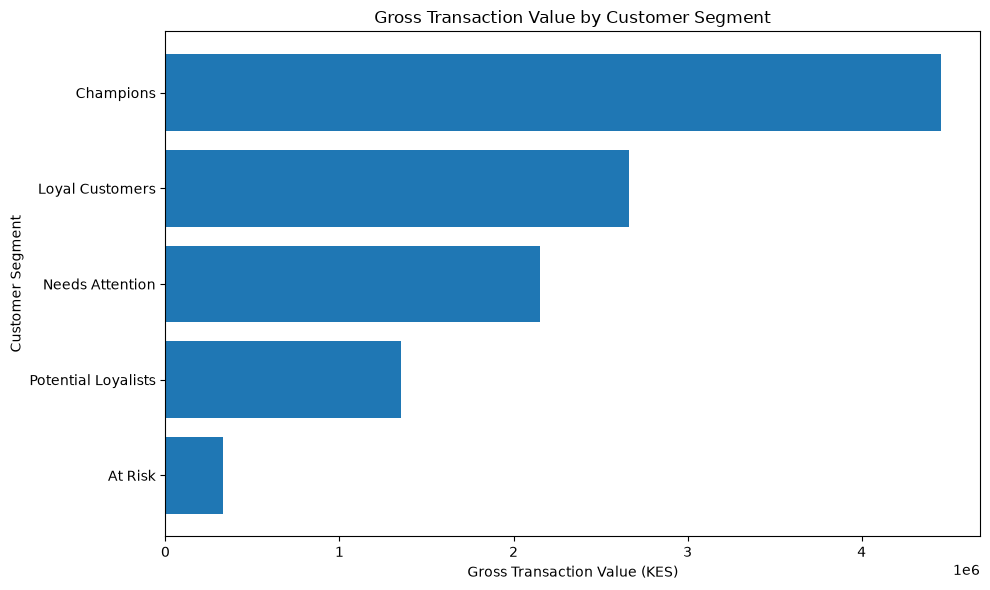

In [19]:
# CUSTOMER SEGMENT GTV VISUALISATION

import matplotlib.pyplot as plt

plot_data = segment_value_analysis.sort_values(
    "gross_transaction_value",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["segment"],
    plot_data["gross_transaction_value"]
)

plt.title("Gross Transaction Value by Customer Segment")
plt.xlabel("Gross Transaction Value (KES)")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

In [21]:
# COHORT RETENTION ANALYSIS

# valid_transactions_df already contains signup_date
cohort_data = valid_transactions_df.copy()

# Confirm required columns exist
print("Required columns available:")
print(cohort_data.columns.tolist())

# Convert dates into monthly periods
cohort_data["cohort_month"] = (
    cohort_data["signup_date"].dt.to_period("M")
)

cohort_data["activity_month"] = (
    cohort_data["txn_date"].dt.to_period("M")
)

# Calculate months since signup
cohort_data["cohort_index"] = (
    (cohort_data["activity_month"].dt.year -
     cohort_data["cohort_month"].dt.year) * 12
    +
    (cohort_data["activity_month"].dt.month -
     cohort_data["cohort_month"].dt.month)
)

# Count each customer once per activity month
cohort_activity = (
    cohort_data[
        ["user_id", "cohort_month", "activity_month", "cohort_index"]
    ]
    .drop_duplicates()
)

# Calculate original signup cohort sizes
cohort_sizes = (
    users.assign(
        cohort_month=users["signup_date"].dt.to_period("M")
    )
    .groupby("cohort_month")["user_id"]
    .nunique()
)

# Count active customers by cohort and month
cohort_counts = cohort_activity.pivot_table(
    index="cohort_month",
    columns="cohort_index",
    values="user_id",
    aggfunc="nunique"
)

# Calculate retention percentages
cohort_retention = (
    cohort_counts.div(cohort_sizes, axis=0) * 100
)

# Display results
print("\nCOHORT SIZES")
display(cohort_sizes)

print("\nCOHORT RETENTION (%)")
display(cohort_retention.round(2))

Required columns available:
['txn_id', 'user_id', 'txn_date', 'product', 'amount', 'signup_date', 'month']

COHORT SIZES


cohort_month
2026-01    773
2026-02    703
2026-03    745
2026-04    779
Freq: M, Name: user_id, dtype: int64


COHORT RETENTION (%)


cohort_index,0,1,2,3,4,5
cohort_month,,,,,,
2026-01,24.71,53.69,55.89,58.34,56.02,33.51
2026-02,29.87,54.91,54.62,59.03,28.73,NaN
2026-03,32.48,55.44,56.91,30.20,NaN,NaN
2026-04,34.92,53.66,28.37,NaN,NaN,NaN


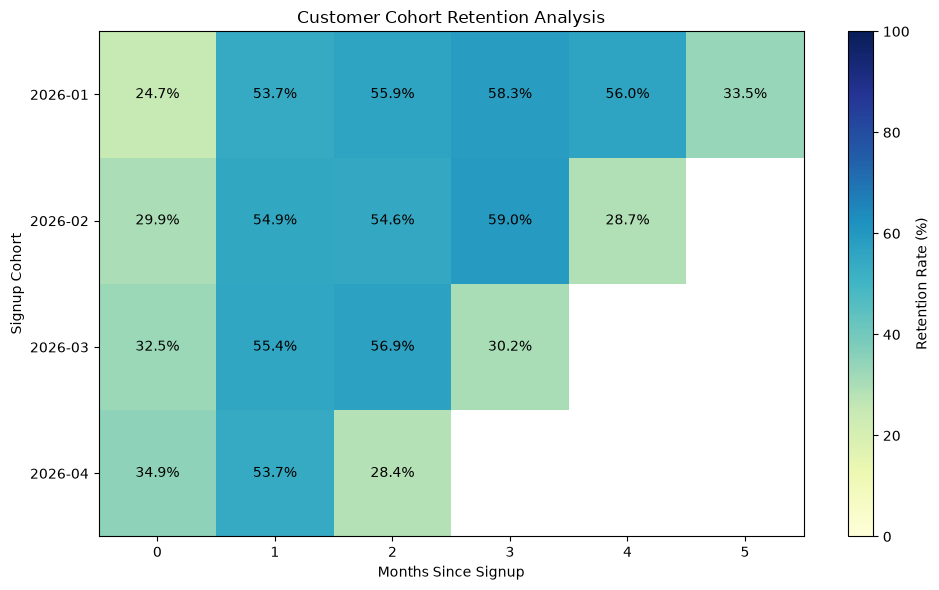

In [22]:
# COHORT RETENTION HEATMAP

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 6))

data = cohort_retention.to_numpy()

image = plt.imshow(
    data,
    aspect="auto",
    cmap="YlGnBu",
    vmin=0,
    vmax=100
)

# Add percentage labels to each available cell
for row in range(data.shape[0]):
    for col in range(data.shape[1]):
        value = data[row, col]

        if not np.isnan(value):
            plt.text(
                col,
                row,
                f"{value:.1f}%",
                ha="center",
                va="center",
                color="black"
            )

plt.title("Customer Cohort Retention Analysis")
plt.xlabel("Months Since Signup")
plt.ylabel("Signup Cohort")

plt.xticks(
    range(len(cohort_retention.columns)),
    cohort_retention.columns
)

plt.yticks(
    range(len(cohort_retention.index)),
    cohort_retention.index.astype(str)
)

plt.colorbar(image, label="Retention Rate (%)")

plt.tight_layout()
plt.show()

In [23]:
# A/B EXPERIMENT: CONVERSION RATE ANALYSIS

experiment_summary = (
    experiment.groupby("group")
    .agg(
        participants=("user_id", "nunique"),
        conversions=("converted", "sum")
    )
)

experiment_summary["conversion_rate"] = (
    experiment_summary["conversions"]
    / experiment_summary["participants"]
    * 100
)

display(experiment_summary.round(2))

# Compare Group B against Group A
rate_a = experiment_summary.loc["A", "conversion_rate"]
rate_b = experiment_summary.loc["B", "conversion_rate"]

absolute_difference = rate_b - rate_a

relative_lift = (
    (rate_b - rate_a) / rate_a
) * 100

print(f"Group A conversion rate: {rate_a:.2f}%")
print(f"Group B conversion rate: {rate_b:.2f}%")
print(f"Absolute difference: {absolute_difference:.2f} percentage points")
print(f"Relative lift: {relative_lift:.2f}%")

,participants,conversions,conversion_rate
group,,,
A,1443,151,10.46
B,1557,215,13.81


Group A conversion rate: 10.46%
Group B conversion rate: 13.81%
Absolute difference: 3.34 percentage points
Relative lift: 31.96%


In [24]:
# A/B EXPERIMENT: CHI-SQUARE SIGNIFICANCE TEST

from scipy.stats import chi2_contingency

# Construct the observed conversion table
contingency_table = pd.crosstab(
    experiment["group"],
    experiment["converted"]
)

print("Observed conversion table:")
display(contingency_table)

# Perform chi-square test
chi2, p_value, degrees_freedom, expected = chi2_contingency(
    contingency_table
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of freedom: {degrees_freedom}")

# Interpret at the 5% significance level
alpha = 0.05

if p_value < alpha:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference.")

Observed conversion table:


converted,0,1
group,,
A,1292,151
B,1342,215


Chi-square statistic: 7.5106
P-value: 0.006134
Degrees of freedom: 1
Result: Statistically significant difference.


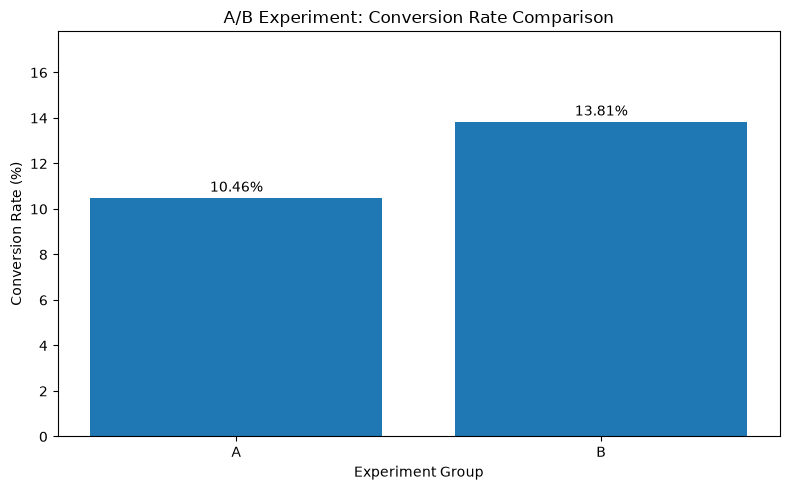

In [25]:
# A/B EXPERIMENT: CONVERSION RATE COMPARISON

import matplotlib.pyplot as plt

groups = ["A", "B"]

conversion_rates = [
    experiment_summary.loc["A", "conversion_rate"],
    experiment_summary.loc["B", "conversion_rate"]
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    groups,
    conversion_rates
)

plt.title("A/B Experiment: Conversion Rate Comparison")
plt.xlabel("Experiment Group")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0, max(conversion_rates) + 4)

# Display percentage labels
for bar, rate in zip(bars, conversion_rates):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{rate:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

A/B EXPERIMENT RESULTS
----------------------------------------
Group A conversion: 10.46%
Group B conversion: 13.81%
Absolute difference: 3.34 percentage points
95% confidence interval: 1.01 to 5.67 percentage points
Chi-square p-value: 0.006134


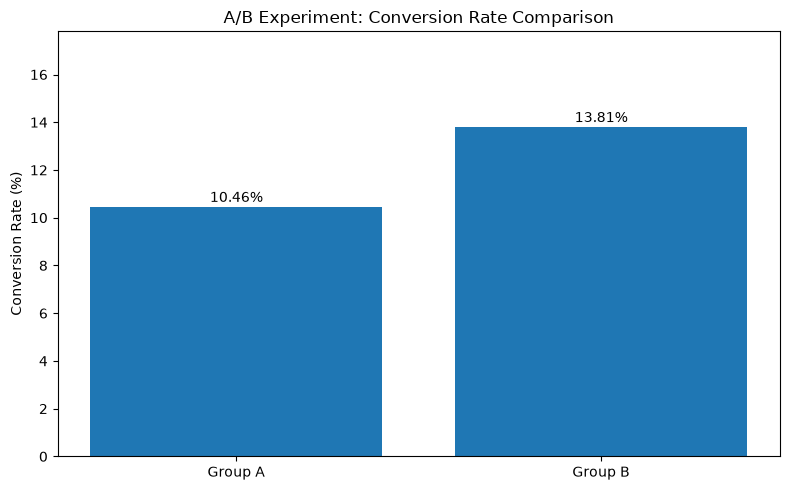

In [26]:
# A/B EXPERIMENT: CONFIDENCE INTERVAL AND VISUALISATION

import matplotlib.pyplot as plt
from scipy.stats import norm

# Extract group results
n_a = int(experiment_summary.loc["A", "participants"])
n_b = int(experiment_summary.loc["B", "participants"])

x_a = int(experiment_summary.loc["A", "conversions"])
x_b = int(experiment_summary.loc["B", "conversions"])

p_a = x_a / n_a
p_b = x_b / n_b

# Difference in conversion rates: B minus A
difference = p_b - p_a

# Standard error for the difference
standard_error = np.sqrt(
    (p_a * (1 - p_a) / n_a) +
    (p_b * (1 - p_b) / n_b)
)

# 95% confidence interval
z_critical = norm.ppf(0.975)

lower_bound = difference - z_critical * standard_error
upper_bound = difference + z_critical * standard_error

print("A/B EXPERIMENT RESULTS")
print("-" * 40)
print(f"Group A conversion: {p_a * 100:.2f}%")
print(f"Group B conversion: {p_b * 100:.2f}%")
print(f"Absolute difference: {difference * 100:.2f} percentage points")
print(f"95% confidence interval: {lower_bound * 100:.2f} to {upper_bound * 100:.2f} percentage points")
print(f"Chi-square p-value: {p_value:.6f}")

# Plot conversion rates
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Group A", "Group B"],
    [p_a * 100, p_b * 100]
)

plt.title("A/B Experiment: Conversion Rate Comparison")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0, max(p_a, p_b) * 100 + 4)

for bar, value in zip(bars, [p_a * 100, p_b * 100]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [27]:
# SQL QUERY EXECUTION AUDIT

sql_text = (PROJECT_DIR / "sql" / "queries.sql").read_text(
    encoding="utf-8"
)

sql_statements = [
    statement.strip()
    for statement in sql_text.split(";")
    if statement.strip()
]

print("SQL statements found:", len(sql_statements))

with sqlite3.connect(DATABASE_PATH) as conn:
    for index, statement in enumerate(sql_statements, start=1):
        result = pd.read_sql_query(statement, conn)

        print(
            f"Statement {index}: PASS "
            f"({len(result)} result rows)"
        )

        display(result.head())

SQL statements found: 9
Statement 1: PASS (3 result rows)


,table_name,record_count
0,users,3000
1,transactions,12000
2,experiment,3000


Statement 2: PASS (1 result rows)


,total_transactions,gross_transaction_value_kes,average_transaction_value_kes
0,12000,15979309.0,1331.61


Statement 3: PASS (6 result rows)


,transaction_month,total_transactions,active_users,gross_transaction_value_kes,average_transaction_value_kes
0,2026-01,1308,1055,1733121.0,1325.02
1,2026-02,2272,1596,2993105.0,1317.39
2,2026-03,2394,1649,3199125.0,1336.31
3,2026-04,2470,1704,3262447.0,1320.83
4,2026-05,2475,1690,3365002.0,1359.60


... (8 outputs left out)

Statement 8: PASS (6 result rows)


,transaction_month,total_transactions,previous_month_transactions,month_over_month_growth_pct
0,2026-01,1308,NaN,NaN
1,2026-02,2272,1308.0,73.70
2,2026-03,2394,2272.0,5.37
3,2026-04,2470,2394.0,3.17
4,2026-05,2475,2470.0,0.20


Statement 9: PASS (3 result rows)


,frequency_segment,customer_count,total_transactions,gross_transaction_value_kes,avg_days_between_transactions
0,High Frequency,632,4348,5779911.0,19.49
1,Medium Frequency,1673,6573,8823037.0,30.91
2,Low Frequency,638,1079,1376361.0,49.57
